# Week 5: Train and compare two models

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. The training and the images run on Replicate, so Colab's free CPU runtime is enough. You will need the course Replicate token, which you can add in Colab's Secrets panel (the key icon on the left) with the name REPLICATE_API_TOKEN. The outputs below are from the 56 museum chairs, trained once with automatic captions and once with captions from the museum records.

## 1. Setup

This reads your Replicate token from Colab's Secrets. If it is not there, it will ask you to paste it.

In [1]:
import csv, io, json, os, sys, time, zipfile
IN_COLAB = "google.colab" in sys.modules
import requests
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

token = os.environ.get("REPLICATE_API_TOKEN")
if IN_COLAB and not token:
    try:
        from google.colab import userdata
        token = userdata.get("REPLICATE_API_TOKEN")
    except Exception:
        token = None
if not token:
    import getpass
    token = getpass.getpass("Replicate token: ")
API = "https://api.replicate.com/v1"
HEADERS = {"Authorization": f"Bearer {token}"}
EXAMPLE = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/"
TRAINER = "ostris/flux-dev-lora-trainer"
H100_PER_SECOND = 0.001525  # Replicate's price for the H100 GPU the trainer runs on (replicate.com/pricing)
owner = requests.get(f"{API}/account", headers=HEADERS, timeout=60).json()["username"]
print("ready")

ready


## 2. Your images

With USE_EXAMPLE = True, it downloads the 56 museum chairs and writes a caption for each from its museum record, for example "a photo of MUSCHR, turned armchair, American, 1650–1700". To use your own, set it to False and run the cell again, and it will ask for a zip of your 20 to 40 images. If you want to compare captions, put a .txt file with the same name next to each image in the zip, with your caption for that image. Change TRIGGER to a made-up word for your set.

56 images, 56 with your own captions


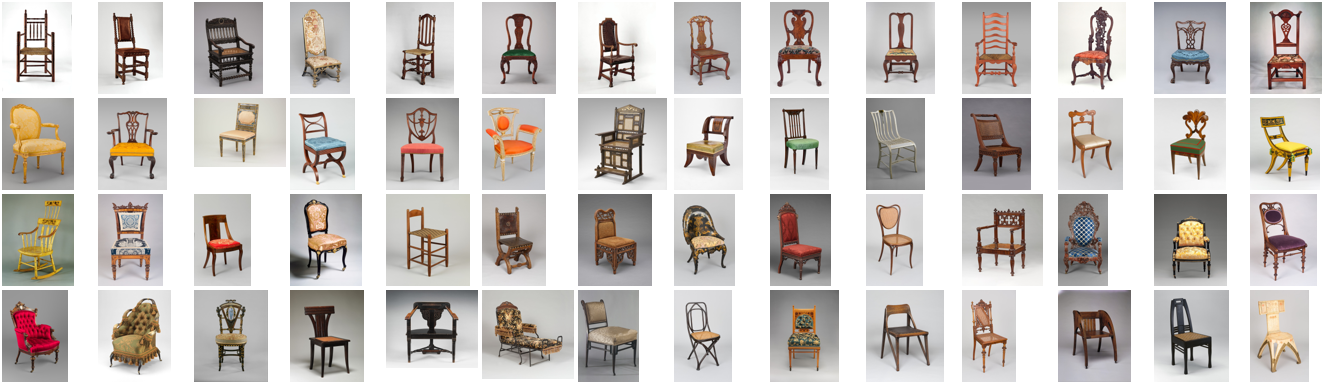

In [2]:
USE_EXAMPLE = True  # True: the 56 museum chairs. False: upload a zip of 20 to 40 of your own images.
TRIGGER = "MUSCHR"  # a made-up word for your set, which goes in every caption and every prompt

own_captions = {}
if USE_EXAMPLE:
    records = list(csv.DictReader(io.StringIO(requests.get(EXAMPLE + "credits.csv", timeout=60).text)))
    images = {r["file"]: requests.get(EXAMPLE + "train/" + r["file"], timeout=60).content for r in records}
    # Captions written from each chair's museum record: its title, maker and date.
    own_captions = {r["file"]: f"a photo of {TRIGGER}, {r['title'].lower()}, {r['maker']}, {r['date']}" for r in records}
else:
    from google.colab import files
    z = zipfile.ZipFile(io.BytesIO(next(iter(files.upload().values()))))
    names = [n for n in z.namelist() if not os.path.basename(n).startswith(".")]
    images = {os.path.basename(n): z.read(n) for n in names if n.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))}
    texts = {os.path.splitext(os.path.basename(n))[0]: z.read(n).decode("utf-8").strip() for n in names if n.lower().endswith(".txt")}
    own_captions = {f: texts[os.path.splitext(f)[0]] for f in images if os.path.splitext(f)[0] in texts}

def sheet(pics, size=96, cols=14):
    out = Image.new("RGB", (cols * size, -(-len(pics) // cols) * size), "white")
    for i, p in enumerate(pics):
        im = Image.open(io.BytesIO(p)).convert("RGB"); im.thumbnail((size - 4, size - 4))
        out.paste(im, ((i % cols) * size + 2, (i // cols) * size + 2))
    return out

print(len(images), "images,", len(own_captions), "with your own captions")
display(sheet(list(images.values())))

## 3. The one thing you change

Set SETTING to "captions", "steps" or "rank", and the two models will differ only in that. With "captions", model A gets captions that the trainer writes automatically and model B gets yours. With "steps", A trains for 500 steps and B for 1,000. With "rank", A has rank 4 and B has rank 16 (the rank is the size of the LoRA, as in the week 5 slides).

In [3]:
SETTING = "captions"  # "captions", "steps" or "rank"

# A and B differ only in SETTING. Everything else stays the same: 1,000 steps, rank 16, the same images.
CHOICES = {"captions": ("automatic", "your own"), "steps": (500, 1000), "rank": (4, 16)}
A, B = CHOICES[SETTING]

def settings(value):
    s = {"trigger_word": TRIGGER, "steps": 1000, "lora_rank": 16,
         "autocaption": True, "autocaption_prefix": f"a photo of {TRIGGER}, "}
    if SETTING == "captions" and value == "your own":
        s["autocaption"] = False
    if SETTING == "steps":
        s["steps"] = value
    if SETTING == "rank":
        s["lora_rank"] = value
    return s

if SETTING == "captions":
    missing = [f for f in images if f not in own_captions]
    assert not missing, f"no caption for {len(missing)} images, e.g. {missing[:3]}: add a .txt file with the same name for each"
    for f in list(images)[:3]:
        print(f, "->", own_captions[f])
print("A:", SETTING, "=", A, " | B:", SETTING, "=", B)

met-146.jpg -> a photo of MUSCHR, turned armchair, American, 1650–1700
met-1540.jpg -> a photo of MUSCHR, side chair, American, 1675–1700
aic-272056.jpg -> a photo of MUSCHR, armchair, Coromandel Coast, probably Madras (Chennai), India, c. 1690–1700
A: captions = automatic  | B: captions = your own


## 4. Train both models

It uploads your images and trains both models on Replicate at the same time, with the trainer ostris/flux-dev-lora-trainer. In the example, each training took 11 to 12 minutes and cost about 1 US dollar. If you run this cell again, it reuses the trainings that already finished.

In [4]:
def make_zip(with_captions):
    buf = io.BytesIO()
    with zipfile.ZipFile(buf, "w") as z:
        for name, data in images.items():
            z.writestr(name, data)
            if with_captions:
                z.writestr(os.path.splitext(name)[0] + ".txt", own_captions[name])
    return buf.getvalue()

def upload(data, filename):
    r = requests.post(f"{API}/files", headers=HEADERS, files={"content": (filename, data, "application/zip")}, timeout=600)
    r.raise_for_status()
    return r.json()["urls"]["get"]

def model_for(value):
    name = f"mlfd-week5-{SETTING}-{str(value).replace(' ', '-')}"
    if requests.get(f"{API}/models/{owner}/{name}", headers=HEADERS, timeout=60).status_code == 404:
        requests.post(f"{API}/models", headers=HEADERS, timeout=60,
                      json={"owner": owner, "name": name, "visibility": "private", "hardware": "gpu-h100"}).raise_for_status()
    return f"{owner}/{name}"

# Trainings that already finished in this session are reused if you run the cell again.
jobs = json.load(open("trainings.json")) if os.path.exists("trainings.json") else {}
version = requests.get(f"{API}/models/{TRAINER}", headers=HEADERS, timeout=60).json()["latest_version"]["id"]
for label, value in (("A", A), ("B", B)):
    key = f"{SETTING}={value}"
    if jobs.get(key, {}).get("status") == "succeeded":
        continue
    url = upload(make_zip(SETTING == "captions" and value == "your own"), f"set-{label}.zip")
    jobs[key] = requests.post(f"{API}/models/{TRAINER}/versions/{version}/trainings", headers=HEADERS, timeout=60,
                              json={"destination": model_for(value), "input": {"input_images": url, **settings(value)}}).json()
    print(label, "started:", key)

t0, last = time.time(), ""
while any(j["status"] not in ("succeeded", "failed", "canceled") for j in jobs.values()):
    time.sleep(30)
    for k, j in jobs.items():
        if j["status"] not in ("succeeded", "failed", "canceled"):
            jobs[k] = requests.get(j["urls"]["get"], headers=HEADERS, timeout=60).json()
    now = ", ".join(f"{k}: {j['status']}" for k, j in jobs.items())
    if now != last:
        print(f"{round((time.time() - t0) / 60)} min  {now}"); last = now
json.dump(jobs, open("trainings.json", "w"))
for label, value in (("A", A), ("B", B)):
    j = jobs[f"{SETTING}={value}"]
    assert j["status"] == "succeeded", j.get("error")
    secs = j["metrics"]["predict_time"]
    print(f"{label} ({SETTING} = {value}): {secs / 60:.0f} min of training, about ${secs * H100_PER_SECOND:.2f}")

A (captions = automatic): 12 min of training, about $1.11
B (captions = your own): 11 min of training, about $1.00


## 5. The same seeds with both models

It makes four images with each model, with the same prompt and the same four seeds, so the only difference between the two rows is the setting you changed. Change PROMPT to describe your own designs, and keep your trigger word in it. For the hand-in, you can download comparison.jpg from the Files panel on the left, and write a few sentences on which model's images look more like your designs (for example the shape, the material or the details), and why you think the setting made that difference.

prompt: a photo of MUSCHR, a side chair, museum object photograph on a plain grey backdrop | seeds: [1, 2, 3, 4]


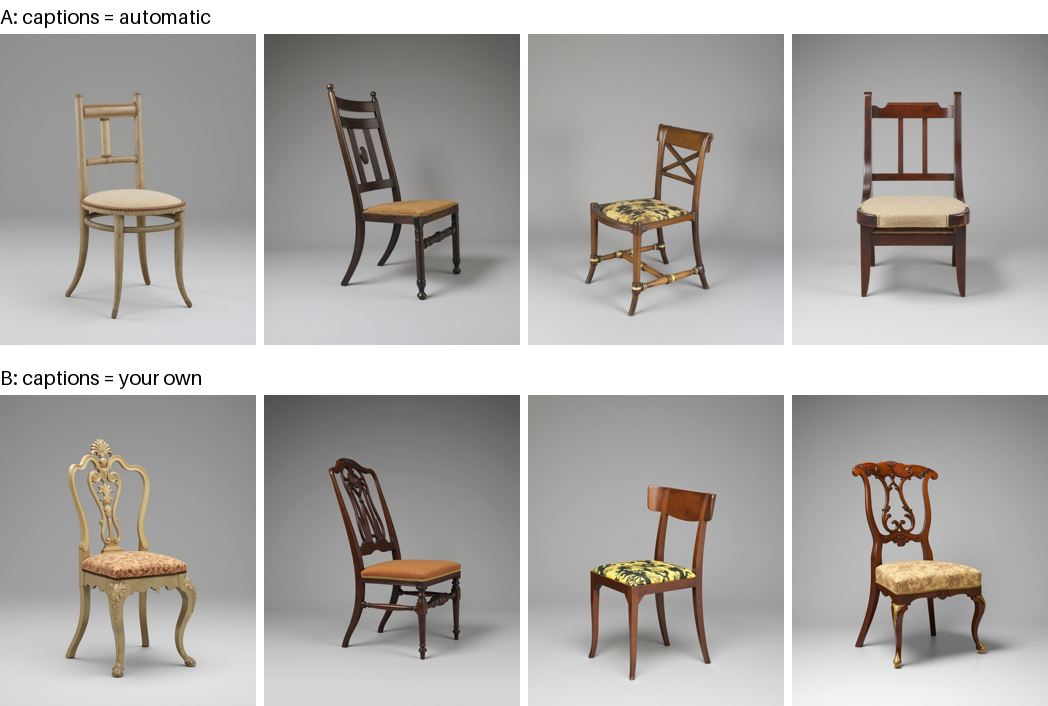

In [5]:
PROMPT = f"a photo of {TRIGGER}, a side chair, museum object photograph on a plain grey backdrop"
SEEDS = [1, 2, 3, 4]

def make_image(version, seed):
    """One image from a trained model, run directly by its version on Replicate."""
    inp = {"prompt": PROMPT, "seed": seed, "lora_scale": 1, "go_fast": False, "aspect_ratio": "4:5",
           "num_inference_steps": 28, "guidance_scale": 3, "output_format": "jpg"}
    r = requests.post(f"{API}/predictions", headers=HEADERS, json={"version": version, "input": inp}, timeout=300).json()
    while r.get("status") not in ("succeeded", "failed", "canceled"):
        time.sleep(2)
        r = requests.get(r["urls"]["get"], headers=HEADERS, timeout=60).json()
    if r["status"] != "succeeded":
        raise RuntimeError(r.get("error"))
    url = r["output"][0] if isinstance(r["output"], list) else r["output"]
    return Image.open(io.BytesIO(requests.get(url, timeout=120).content)).convert("RGB")

def row(pics, label, w=256):
    h = round(w * pics[0].height / pics[0].width)
    out = Image.new("RGB", (len(pics) * (w + 8) - 8, h + 34), "white")
    ImageDraw.Draw(out).text((0, 4), label, fill="black", font=ImageFont.load_default(20))
    for i, p in enumerate(pics):
        out.paste(p.resize((w, h)), (i * (w + 8), 34))
    return out

rows = []
for label, value in (("A", A), ("B", B)):
    trained = jobs[f"{SETTING}={value}"]["output"]["version"].split(":")[1]
    pics = [make_image(trained, s) for s in SEEDS]
    for s, p in zip(SEEDS, pics):
        p.save(f"{label}-seed-{s}.jpg")
    rows.append(row(pics, f"{label}: {SETTING} = {value}"))
both = Image.new("RGB", (rows[0].width, sum(r.height for r in rows) + 16), "white")
both.paste(rows[0], (0, 0)); both.paste(rows[1], (0, rows[0].height + 16))
both.save("comparison.jpg")
print("prompt:", PROMPT, "| seeds:", SEEDS)
both

## 6. Both models on your map

It places the images from both models on a map of your training images, like the map in week 4, with model A's images outlined in orange and model B's in green. Look at which of your designs each model's images land next to. CLIP runs on the CPU, so this takes a minute or two.

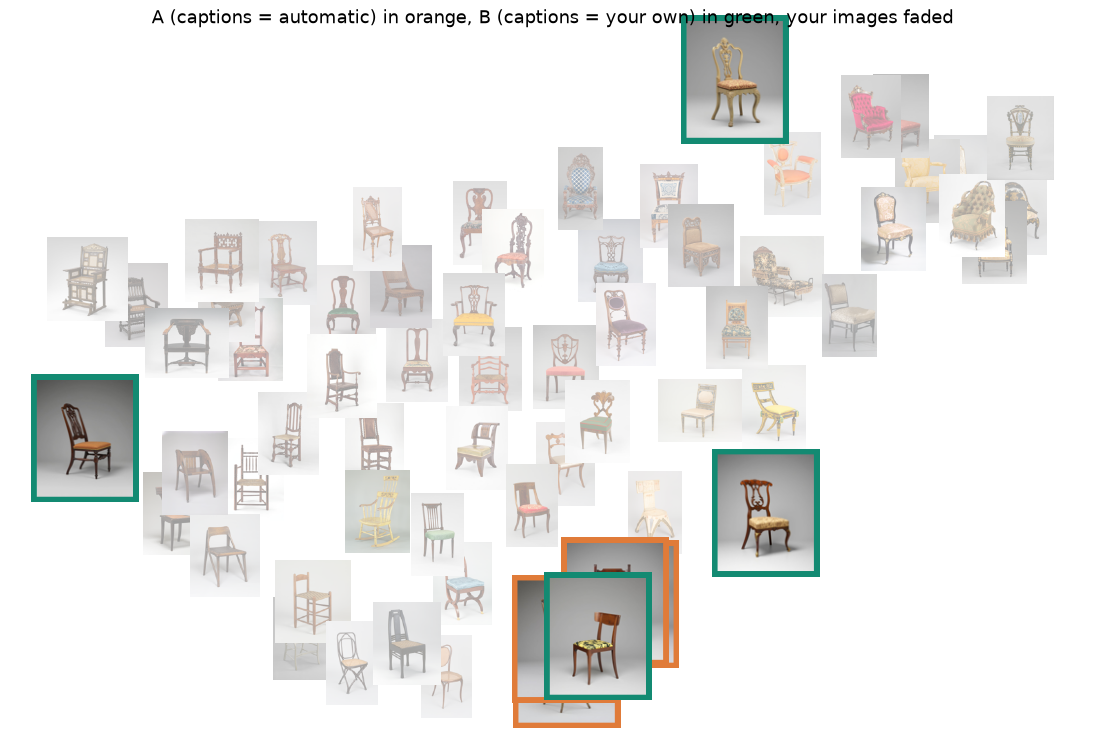

In [6]:
if IN_COLAB:
    !pip -q install umap-learn
import numpy as np, torch, umap
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import ImageOps
from transformers import CLIPModel, CLIPProcessor

dev = "cuda" if torch.cuda.is_available() else "cpu"
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
train_pics = [Image.open(io.BytesIO(b)).convert("RGB") for b in images.values()]
made = {label: [Image.open(f"{label}-seed-{s}.jpg").convert("RGB") for s in SEEDS] for label in ("A", "B")}

def clip_embed(pics):
    out = []
    with torch.no_grad():
        for i in range(0, len(pics), 16):
            e = clip.get_image_features(**cproc(images=pics[i:i + 16], return_tensors="pt").to(dev))
            if not torch.is_tensor(e):  # newer versions of transformers return an object
                e = e.image_embeds if getattr(e, "image_embeds", None) is not None else e.pooler_output
                if e.shape[-1] != clip.config.projection_dim:
                    e = clip.visual_projection(e)
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

reducer = umap.UMAP(n_neighbors=min(15, len(train_pics) - 1), min_dist=0.3, metric="cosine", random_state=0)
xy = reducer.fit_transform(clip_embed(train_pics))
made_xy = {label: reducer.transform(clip_embed(pics)) for label, pics in made.items()}
COLORS = {"A": "#E07B39", "B": "#138A72"}

def thumb(ax, im, x, y, size=0.5, faded=False, border=None):
    im = im.copy(); im.thumbnail((120, 120))
    if faded:
        im = Image.blend(im, Image.new("RGB", im.size, "white"), 0.6)
    if border:
        im = ImageOps.expand(im, border=6, fill=border)
    ax.add_artist(AnnotationBbox(OffsetImage(np.asarray(im), zoom=size), (x, y), frameon=False))

fig, ax = plt.subplots(figsize=(14, 9))
for (x, y), im in zip(xy, train_pics):
    thumb(ax, im, x, y, faded=True)
for label, pics in made.items():
    for (x, y), im in zip(made_xy[label], pics):
        thumb(ax, im, x, y, size=0.7, border=COLORS[label])
allxy = np.vstack([xy, *made_xy.values()])
pad = (allxy.max(0) - allxy.min(0)) * 0.08
ax.set_xlim(allxy[:, 0].min() - pad[0], allxy[:, 0].max() + pad[0])
ax.set_ylim(allxy[:, 1].min() - pad[1], allxy[:, 1].max() + pad[1])
ax.set_title(f"A ({SETTING} = {A}) in orange, B ({SETTING} = {B}) in green, your images faded", fontsize=13)
ax.axis("off")
plt.savefig("map.jpg", dpi=120, bbox_inches="tight")
plt.show()

## 7. The closest training image

Under each image from the two models, it shows the closest training image (found with DINOv2) and their similarity score. It first prints the median similarity between each training image and its closest other training image, which shows how similar your own images are to each other. If a pair scores near that number or above it, look at the two images and check whether that model copied one of yours. For the hand-in, you can add map.jpg and closest.jpg next to comparison.jpg.

Each training image and its closest other training image: median similarity 0.85


A: each image and its closest training image, median similarity 0.85


B: each image and its closest training image, median similarity 0.89


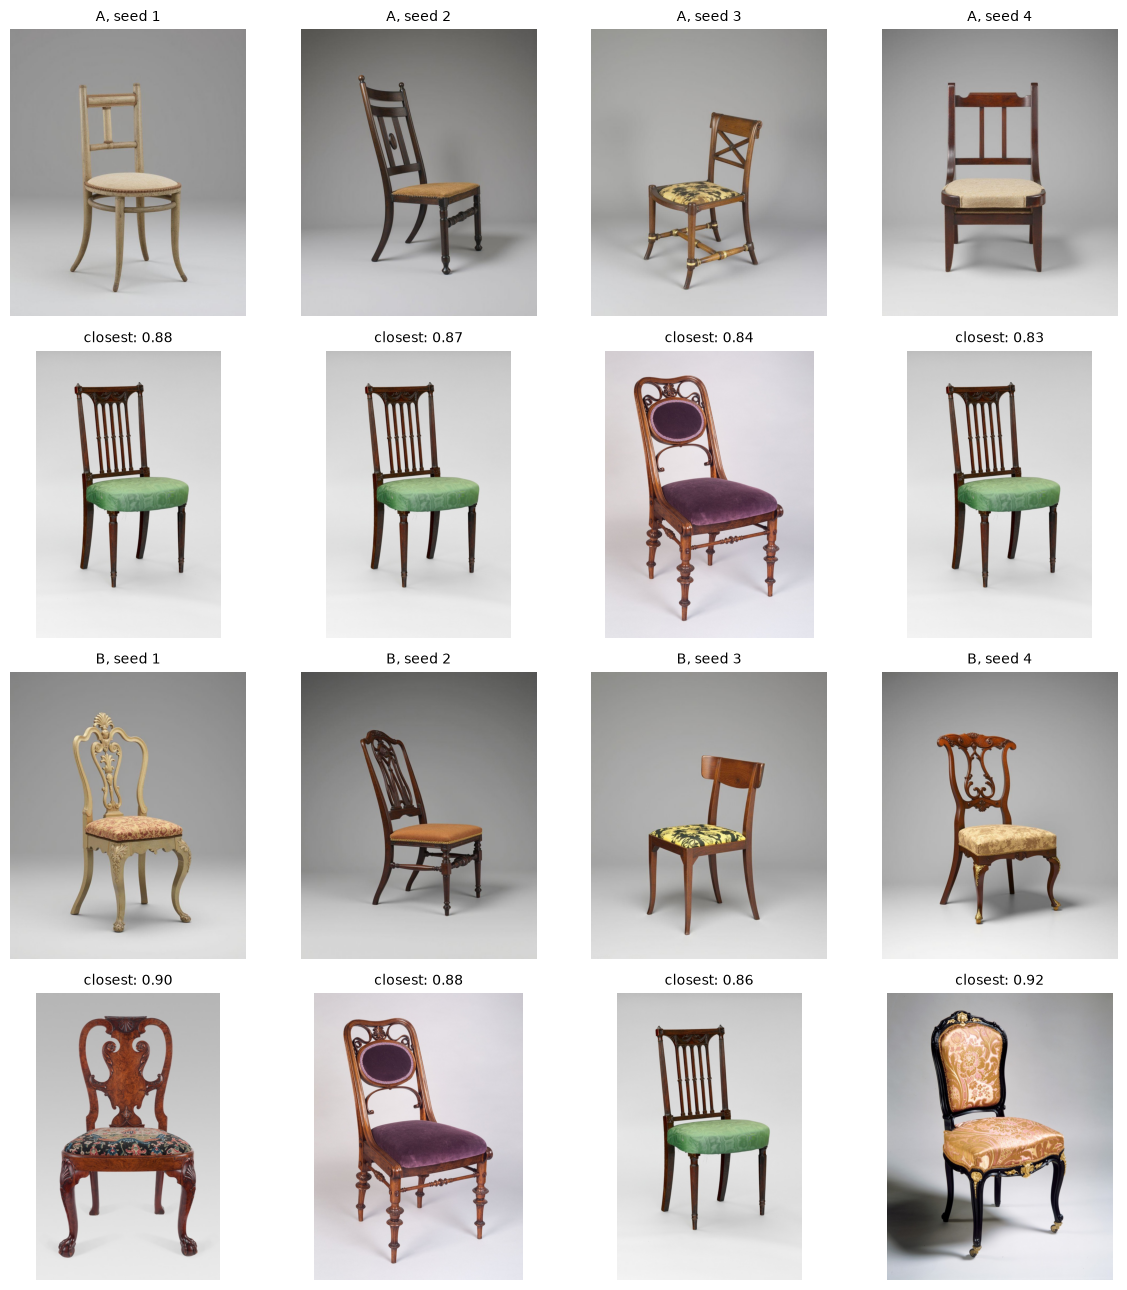

In [7]:
# DINOv2 is trained on images alone, and matches by how things look more closely than CLIP does.
from transformers import AutoImageProcessor, AutoModel
dproc = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
dino = AutoModel.from_pretrained("facebook/dinov2-base").to(dev).eval()

def dino_embed(pics):
    out = []
    with torch.no_grad():
        for i in range(0, len(pics), 8):
            e = dino(**dproc(images=pics[i:i + 8], return_tensors="pt").to(dev)).pooler_output
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

DT = dino_embed(train_pics)
TT = DT @ DT.T
np.fill_diagonal(TT, -1)
print(f"Each training image and its closest other training image: median similarity {np.median(TT.max(1)):.2f}")
fig, axes = plt.subplots(4, len(SEEDS), figsize=(3 * len(SEEDS), 13), squeeze=False)
for r, (label, pics) in enumerate(made.items()):
    S = dino_embed(pics) @ DT.T
    print(f"{label}: each image and its closest training image, median similarity {np.median(S.max(1)):.2f}")
    for i, p in enumerate(pics):
        j = int(S[i].argmax())
        for k, (im, title) in enumerate([(p, f"{label}, seed {SEEDS[i]}"), (train_pics[j], f"closest: {S[i, j]:.2f}")]):
            ax = axes[2 * r + k, i]
            ax.imshow(im); ax.set_title(title, fontsize=10); ax.axis("off")
plt.tight_layout()
plt.savefig("closest.jpg", dpi=110)
plt.show()